# DATA 266 · HW11 · Part 2 — Knowledge distillation (BERT teacher → DistilBERT student) on AG News

**Student:** Ritika Mukesh Neema · SID4 6638

Pipeline:
1. Download the instructor's fine-tuned BERT teacher (`teacher_model.7z`) and load it locally.
2. Run the teacher once over **all 120,000 AG News training samples** and cache its logits.
3. Train `distilbert-base-uncased` students with the distillation loss

$$\mathcal{L} \;=\; \alpha\,\mathrm{CE}\big(z_s,\,y\big) \;+\; (1-\alpha)\,T^2\,\mathrm{KL}\!\big(\mathrm{softmax}(z_t/T)\,\big\|\,\mathrm{softmax}(z_s/T)\big)$$

   where $z_s, z_t$ are student/teacher logits, $T$ is the temperature ($T=1$ = no softening) and $\alpha$ weights the hard-label cross-entropy. The $T^2$ factor keeps the KL gradient scale comparable across temperatures (Hinton et al., 2015).
4. Temperature sweep at fixed $\alpha$, then an $\alpha$ sweep at the best $T$. Every run re-initialises the student from the same pretrained checkpoint with `SEED`, the same data order and the same settings.
5. Evaluate teacher and best student on the same AG News test set and hardware: accuracy, per-class accuracy, inference time, model size; inspect where compression hurts.

**Model selection:** 5% of the training set (seeded) is held out as a validation split. The best $T$ and $\alpha$ are chosen on **validation** accuracy so the test set is not used for tuning; test accuracy is reported for every run.

**Runtime:** Colab → T4 GPU. Expected total: roughly 45–75 min (teacher logits ≈ 3–5 min, each student run ≈ 4–8 min × 7 runs).

In [2]:
%pip install -q -U gdown py7zr datasets

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [3]:
from google.colab import auth; auth.authenticate_user()
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
import io
req = build("drive", "v3").files().get_media(fileId="1Sdhyi0rr7XQn_pm-H0XkEfOkCzEp9Agp")
with io.FileIO("teacher_model.7z", "wb") as fh:
    dl, done = MediaIoBaseDownload(fh, req, chunksize=64 * 2**20), False
    while not done:
        status, done = dl.next_chunk(); print(f"\r{int(status.progress()*100)}%", end="")

100%

## Step 0 — SID-derived parameters (same as Assignment 1)

In [4]:
import os, gc, json, time, random, shutil, subprocess, platform
import numpy as np
import torch, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SID4  = 6638
SEED  = 6638          # SID4
SLICE = 638           # SID4 % 1000
HP_ID = 2             # SID4 % 6   (HW11: HP_ID does not add another temperature)
CLS_A = 8             # SID4 % 10
CLS_B = 5             # (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

def set_seeds(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seeds()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"            # fp16 autocast on GPU (T4 has no bf16)
os.makedirs("figs", exist_ok=True); os.makedirs("artifacts", exist_ok=True); os.makedirs("logs", exist_ok=True)

RUN_LOG = []
def log(msg):
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line); RUN_LOG.append(line)

import transformers, datasets
log(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
log(f"python={platform.python_version()} torch={torch.__version__} transformers={transformers.__version__} datasets={datasets.__version__}")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
log(f"device={DEVICE} ({GPU_NAME}) amp={USE_AMP}")

[23:43:49] SID4=6638 SEED=6638 SLICE=638 HP_ID=2 CLS_A=8 CLS_B=5
[23:43:49] python=3.13.16 torch=2.14.1+cu130 transformers=5.22.1 datasets=5.2.0
[23:43:49] device=cuda (Tesla T4) amp=True


## Configuration

All training settings below are **fixed across every run**; only `T` and `α` change between sweeps.

In [5]:
TEACHER_FILE_ID  = "1xBFbHoD1oL2NFAinevXbbHqSHYMcUwhw"   # teacher_model.7z (instructor Drive)
TEACHER_ARCHIVE  = "teacher_model.7z"
TEACHER_EXTRACT  = "teacher_model"
STUDENT_ID       = "distilbert/distilbert-base-uncased"
AG_NEWS_ID       = "fancyzhx/ag_news"
CLASS_NAMES      = ["World", "Sports", "Business", "Sci/Tech"]

# Sweeps
T_SWEEP            = [1, 2, 4, 8]          # temperatures; T=1 is the no-softening baseline
ALPHA_FOR_T_SWEEP  = 0.5                   # alpha held fixed during the temperature sweep
ALPHA_SWEEP        = [0.25, 0.5, 0.75]     # alpha values at the best T

# Fixed training settings (identical for every student)
MAX_LEN      = 128
BATCH_SIZE   = 32
EPOCHS       = 2
LR           = 5e-5
WEIGHT_DECAY = 0.01
WARMUP_FRAC  = 0.06
GRAD_CLIP    = 1.0
VAL_FRAC     = 0.05
LOG_EVERY    = 200          # steps between training-log lines

# Inference measurement (identical for teacher and student)
EVAL_BATCH   = 64
N_LATENCY    = 200          # single-example latency samples (batch 1)
NUM_WORKERS  = 2

## Load AG News

In [6]:
from datasets import load_dataset
try:
    ag = load_dataset(AG_NEWS_ID)
except Exception as e:
    log(f"{AG_NEWS_ID} failed ({e}); trying 'ag_news'"); ag = load_dataset("ag_news")
train_texts, train_labels = list(ag["train"]["text"]), np.array(ag["train"]["label"])
test_texts,  test_labels  = list(ag["test"]["text"]),  np.array(ag["test"]["label"])
log(f"AG News: train={len(train_texts):,}  test={len(test_texts):,}  "
    f"train class counts={np.bincount(train_labels).tolist()}  test class counts={np.bincount(test_labels).tolist()}")

# Seeded train/validation split (indices refer to the full training set)
perm = np.random.default_rng(SEED).permutation(len(train_texts))
n_val = int(VAL_FRAC * len(train_texts))
VAL_IDX, TRN_IDX = np.sort(perm[:n_val]), np.sort(perm[n_val:])
log(f"student training split: train={len(TRN_IDX):,}  val={len(VAL_IDX):,}")

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

[23:44:01] AG News: train=120,000  test=7,600  train class counts=[30000, 30000, 30000, 30000]  test class counts=[1900, 1900, 1900, 1900]
[23:44:01] student training split: train=114,000  val=6,000


## Download and load the teacher

Downloads `teacher_model.7z` from the instructor's Drive link with `gdown`. If the download is blocked (Drive quota), add the file to your own Drive, mount it, and set `TEACHER_ARCHIVE` to its path; the cell skips the download when the archive already exists.

In [7]:
import gdown
if not os.path.exists(TEACHER_ARCHIVE):
    gdown.download(id=TEACHER_FILE_ID, output=TEACHER_ARCHIVE, quiet=False)
log(f"teacher archive: {TEACHER_ARCHIVE} ({os.path.getsize(TEACHER_ARCHIVE)/2**20:.1f} MiB)")

if not os.path.isdir(TEACHER_EXTRACT):
    if shutil.which("7z"):
        subprocess.run(["7z", "x", "-y", f"-o{TEACHER_EXTRACT}", TEACHER_ARCHIVE], check=True, stdout=subprocess.DEVNULL)
    else:
        import py7zr
        with py7zr.SevenZipFile(TEACHER_ARCHIVE, "r") as z: z.extractall(TEACHER_EXTRACT)

WEIGHT_FILES = {"model.safetensors", "pytorch_model.bin", "model.safetensors.index.json", "pytorch_model.bin.index.json"}
cands = [r for r, _, fs in os.walk(TEACHER_EXTRACT) if "config.json" in fs and WEIGHT_FILES & set(fs)]
assert cands, f"no config.json + weights found under {TEACHER_EXTRACT}"
TEACHER_DIR = sorted(cands, key=len)[0]
log(f"teacher folder: {TEACHER_DIR} -> {sorted(os.listdir(TEACHER_DIR))}")

[23:44:01] teacher archive: teacher_model.7z (383.1 MiB)
[23:44:37] teacher folder: teacher_model/teacher_model -> ['__MACOSX', 'config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']


In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
try:
    t_tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
except Exception as e:
    t_tok = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")
    log(f"WARNING: no tokenizer in teacher folder ({e}); using bert-base-uncased")
s_tok = AutoTokenizer.from_pretrained(STUDENT_ID)

t_params = sum(p.numel() for p in teacher.parameters())
log(f"teacher: {teacher.config.model_type} / {type(teacher).__name__}, num_labels={teacher.config.num_labels}, "
    f"params={t_params/1e6:.1f}M, id2label={teacher.config.id2label}")
assert teacher.config.num_labels == 4

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[23:45:05] teacher: bert / BertForSequenceClassification, num_labels=4, params=109.5M, id2label={0: 'WORLD', 1: 'SPORTS', 2: 'BUSINESS', 3: 'SCI/TECH'}


## Tokenisation, data loaders and shared evaluation helpers

In [9]:
def encode(tok, texts, bs=4096):
    out = []
    for i in range(0, len(texts), bs):
        out.extend(tok(texts[i:i+bs], truncation=True, max_length=MAX_LEN)["input_ids"])
    return out

class Encoded(Dataset):
    def __init__(self, ids, labels, index):
        self.ids, self.labels, self.index = ids, labels, index
    def __len__(self): return len(self.index)
    def __getitem__(self, i):
        j = self.index[i]
        return self.ids[j], int(self.labels[j]), int(j)

def make_collate(pad_id):
    def collate(batch):
        L = max(len(b[0]) for b in batch)
        ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
        mask = torch.zeros((len(batch), L), dtype=torch.long)
        for k, (x, _, _) in enumerate(batch):
            ids[k, :len(x)] = torch.tensor(x); mask[k, :len(x)] = 1
        y = torch.tensor([b[1] for b in batch]); idx = torch.tensor([b[2] for b in batch])
        return ids, mask, y, idx
    return collate

def eval_loader(tok, ids, labels, index, bs=EVAL_BATCH):
    # Length-sorted order makes padding minimal; predictions are scattered back to their original index.
    order = sorted(index, key=lambda j: len(ids[j]))
    return DataLoader(Encoded(ids, labels, order), batch_size=bs, shuffle=False,
                      collate_fn=make_collate(tok.pad_token_id), num_workers=NUM_WORKERS)

@torch.no_grad()
def predict_logits(model, loader, n_total):
    model.eval()
    out = torch.zeros((n_total, 4), dtype=torch.float32)
    for ids, mask, _, idx in loader:
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
            z = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        out[idx] = z.float().cpu()
    return out

def per_class_acc(y, p):
    return {CLASS_NAMES[c]: float((p[y == c] == c).mean()) for c in range(4)}

t0 = time.time()
t_train_ids = encode(t_tok, train_texts); t_test_ids = encode(t_tok, test_texts)
s_train_ids = encode(s_tok, train_texts); s_test_ids = encode(s_tok, test_texts)
log(f"tokenised train/test for teacher and student in {time.time()-t0:.1f}s "
    f"(student mean length {np.mean([len(x) for x in s_train_ids]):.1f} tokens, truncated at {MAX_LEN})")

[23:45:53] tokenised train/test for teacher and student in 48.2s (student mean length 52.8 tokens, truncated at 128)


### Teacher label order check

The teacher was trained by someone else, so before using its logits we confirm its output columns line up with AG News label ids (0 World, 1 Sports, 2 Business, 3 Sci/Tech). On a seeded sample of 2,000 training texts, each teacher column is mapped to the true label it most often coincides with; if that mapping is a non-identity permutation, the logit columns are reordered.

In [10]:
chk_idx = np.sort(np.random.default_rng(SEED).choice(len(train_texts), min(2000, len(train_texts)), replace=False)).tolist()
z_chk = predict_logits(teacher, eval_loader(t_tok, t_train_ids, train_labels, chk_idx), len(train_texts))[chk_idx]
pred_chk = z_chk.argmax(1).numpy(); y_chk = train_labels[chk_idx]
cm = np.zeros((4, 4), int)
for a, b in zip(y_chk, pred_chk): cm[a, b] += 1
col_to_label = cm.argmax(0)
if sorted(col_to_label.tolist()) == [0, 1, 2, 3] and not (col_to_label == np.arange(4)).all():
    LABEL_PERM = np.argsort(col_to_label)       # new column l <- teacher column with col_to_label == l
    log(f"teacher columns are permuted: col->label {col_to_label.tolist()}; reordering logits")
else:
    LABEL_PERM = np.arange(4)
acc_chk = (col_to_label[pred_chk] == y_chk).mean()
log(f"teacher sanity check on 2,000 train samples: accuracy={acc_chk:.4f}; confusion (rows=true, cols=teacher col):\n{cm}")
assert acc_chk > 0.5, "teacher accuracy is near chance - check the teacher folder / tokenizer"

[23:45:56] teacher sanity check on 2,000 train samples: accuracy=0.9870; confusion (rows=true, cols=teacher col):
[[495   0   7   3]
 [  1 510   0   0]
 [  2   0 501   7]
 [  0   0   6 468]]


## Extract teacher logits for all 120,000 training samples

In [11]:
LOGITS_PATH = "artifacts/teacher_train_logits.pt"
if os.path.exists(LOGITS_PATH):
    TEACHER_LOGITS = torch.load(LOGITS_PATH)
    log(f"loaded cached teacher logits {tuple(TEACHER_LOGITS.shape)}")
else:
    t0 = time.time()
    all_idx = list(range(len(train_texts)))
    TEACHER_LOGITS = predict_logits(teacher, eval_loader(t_tok, t_train_ids, train_labels, all_idx, bs=256), len(train_texts))
    TEACHER_LOGITS = TEACHER_LOGITS[:, LABEL_PERM].contiguous()
    torch.save(TEACHER_LOGITS, LOGITS_PATH)
    log(f"teacher logits for {TEACHER_LOGITS.shape[0]:,} train samples in {time.time()-t0:.1f}s -> {LOGITS_PATH}")
t_train_acc = (TEACHER_LOGITS.argmax(1).numpy() == train_labels).mean()
log(f"teacher accuracy on the full training set: {t_train_acc:.4f}")

[23:47:08] teacher logits for 120,000 train samples in 72.0s -> artifacts/teacher_train_logits.pt
[23:47:08] teacher accuracy on the full training set: 0.9895


## Shared inference benchmark (teacher and student)

Same test set, same GPU, same precision (fp16 autocast), same batching:
- **Throughput:** full 7,600-example test set at batch size `EVAL_BATCH` (wall-clock, including tokenised-batch transfer).
- **Latency:** `N_LATENCY` single examples at batch size 1 → p50 / p95.
- **Memory:** peak GPU memory during the benchmark (model weights + activations).
- **Size:** parameter count and on-disk size after `save_pretrained` (safetensors, fp32).

In [12]:
def _sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

def dir_size_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 2**20

@torch.no_grad()
def benchmark(model, tok, test_ids, name, save_dir, label_perm=None):
    model.eval()
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    loader = eval_loader(tok, test_ids, test_labels, list(range(len(test_ids))))
    predict_logits(model, eval_loader(tok, test_ids, test_labels, list(range(256))), len(test_ids))  # warm-up
    _sync(); t0 = time.perf_counter()
    logits = predict_logits(model, loader, len(test_ids))
    _sync(); total_s = time.perf_counter() - t0
    if label_perm is not None:
        logits = logits[:, label_perm]          # align teacher columns with AG News label ids
    preds = logits.argmax(1).numpy()

    lat_idx = np.random.default_rng(SEED).choice(len(test_ids), N_LATENCY, replace=False)
    times = []
    for j in lat_idx:
        x = torch.tensor([test_ids[j]], device=DEVICE)
        _sync(); t1 = time.perf_counter()
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
            model(input_ids=x, attention_mask=torch.ones_like(x))
        _sync(); times.append((time.perf_counter() - t1) * 1000)

    peak_mib = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
    model.save_pretrained(save_dir)
    rec = {"name": name, "test_accuracy": float((preds == test_labels).mean()),
           "per_class_accuracy": per_class_acc(test_labels, preds),
           "test_set_seconds": total_s, "throughput_samples_per_s": len(test_ids) / total_s,
           "latency_p50_ms": float(np.percentile(times, 50)), "latency_p95_ms": float(np.percentile(times, 95)),
           "peak_gpu_mib": peak_mib,
           "params_m": sum(p.numel() for p in model.parameters()) / 1e6, "disk_mib": dir_size_mb(save_dir)}
    log(f"[{name}] test acc={rec['test_accuracy']:.4f}  test-set time={total_s:.2f}s "
        f"({rec['throughput_samples_per_s']:.0f}/s)  latency p50={rec['latency_p50_ms']:.2f}ms p95={rec['latency_p95_ms']:.2f}ms  "
        f"peak GPU={peak_mib:.0f}MiB  params={rec['params_m']:.1f}M  disk={rec['disk_mib']:.1f}MiB")
    return rec, preds, logits

In [13]:
teacher_rec, teacher_preds, teacher_test_logits = benchmark(teacher, t_tok, t_test_ids, "teacher_bert",
                                                            "artifacts/teacher_saved", label_perm=LABEL_PERM)
log(f"teacher per-class test accuracy: {teacher_rec['per_class_accuracy']}")

del teacher; gc.collect()
if DEVICE == "cuda": torch.cuda.empty_cache()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[23:47:23] [teacher_bert] test acc=0.9443  test-set time=6.07s (1251/s)  latency p50=29.75ms p95=56.91ms  peak GPU=796MiB  params=109.5M  disk=417.7MiB
[23:47:23] teacher per-class test accuracy: {'World': 0.9489473684210527, 'Sports': 0.988421052631579, 'Business': 0.9136842105263158, 'Sci/Tech': 0.9263157894736842}


## Distillation loss and training loop

`kd_loss` returns the weighted total plus its two parts so CE and KL can be tracked separately. Logits are cast to fp32 before the softmax/KL so the loss is computed in full precision under autocast.

In [14]:
def kd_loss(student_logits, teacher_logits, labels, T, alpha):
    ce = F.cross_entropy(student_logits, labels)
    kl = F.kl_div(F.log_softmax(student_logits / T, dim=-1),
                  F.log_softmax(teacher_logits / T, dim=-1),
                  reduction="batchmean", log_target=True) * (T * T)
    return alpha * ce + (1 - alpha) * kl, ce, kl

# quick unit checks: identical logits -> KL = 0; alpha=1 -> pure CE
_z = torch.randn(8, 4); _y = torch.randint(0, 4, (8,))
assert abs(kd_loss(_z, _z, _y, 2.0, 0.5)[2].item()) < 1e-6
assert torch.isclose(kd_loss(_z, torch.randn(8, 4), _y, 4.0, 1.0)[0], F.cross_entropy(_z, _y))

from transformers import get_linear_schedule_with_warmup
s_collate = make_collate(s_tok.pad_token_id)
train_set = Encoded(s_train_ids, train_labels, TRN_IDX.tolist())
val_loader  = eval_loader(s_tok, s_train_ids, train_labels, VAL_IDX.tolist())
test_loader = eval_loader(s_tok, s_test_ids, test_labels, list(range(len(test_texts))))

def fresh_student():
    return AutoModelForSequenceClassification.from_pretrained(
        STUDENT_ID, num_labels=4,
        id2label={i: n for i, n in enumerate(CLASS_NAMES)}, label2id={n: i for i, n in enumerate(CLASS_NAMES)})

def train_student(T, alpha, run_name):
    set_seeds(SEED)                                   # same init for the classifier head
    model = fresh_student().to(DEVICE)                # re-initialised from the same pretrained checkpoint
    g = torch.Generator().manual_seed(SEED)           # same data order every run
    loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, generator=g,
                        collate_fn=s_collate, num_workers=NUM_WORKERS)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * len(loader)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total_steps), total_steps)
    scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)

    log(f"== {run_name}: T={T} alpha={alpha} | {EPOCHS} epochs x {len(loader)} steps, bs={BATCH_SIZE}, lr={LR}")
    history, step, t0 = [], 0, time.time()
    acc = {"loss": 0.0, "ce": 0.0, "kl": 0.0, "n": 0}
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for ids, mask, y, idx in loader:
            ids, mask, y = ids.to(DEVICE), mask.to(DEVICE), y.to(DEVICE)
            t_logits = TEACHER_LOGITS[idx].to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
                s_logits = model(input_ids=ids, attention_mask=mask).logits
            loss, ce, kl = kd_loss(s_logits.float(), t_logits, y, T, alpha)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            acc["loss"] += loss.item(); acc["ce"] += ce.item(); acc["kl"] += kl.item(); acc["n"] += 1
            if step % LOG_EVERY == 0 or step == total_steps:
                rec = {"step": step, "epoch": epoch, "loss": acc["loss"] / acc["n"], "ce": acc["ce"] / acc["n"],
                       "kl": acc["kl"] / acc["n"], "lr": sched.get_last_lr()[0], "elapsed_s": time.time() - t0}
                history.append(rec); acc = {"loss": 0.0, "ce": 0.0, "kl": 0.0, "n": 0}
                log(f"  [{run_name}] ep {epoch} step {step:>5}/{total_steps}  loss={rec['loss']:.4f}  "
                    f"ce={rec['ce']:.4f}  kl={rec['kl']:.4f}  lr={rec['lr']:.2e}  {rec['elapsed_s']:.0f}s")
        z_val = predict_logits(model, val_loader, len(train_texts))[VAL_IDX]
        log(f"  [{run_name}] end of epoch {epoch}: val acc={(z_val.argmax(1).numpy() == train_labels[VAL_IDX]).mean():.4f}")

    train_s = time.time() - t0
    val_acc = float((z_val.argmax(1).numpy() == train_labels[VAL_IDX]).mean())
    test_pred = predict_logits(model, test_loader, len(test_texts)).argmax(1).numpy()
    result = {"run": run_name, "T": T, "alpha": alpha, "val_accuracy": val_acc,
              "test_accuracy": float((test_pred == test_labels).mean()),
              "per_class_test_accuracy": per_class_acc(test_labels, test_pred),
              "train_minutes": train_s / 60, "final_loss": history[-1]["loss"],
              "final_ce": history[-1]["ce"], "final_kl": history[-1]["kl"]}
    log(f"== {run_name} done in {train_s/60:.1f} min: val acc={val_acc:.4f}  test acc={result['test_accuracy']:.4f}")
    import pandas as pd
    pd.DataFrame(history).to_csv(f"logs/train_log_{run_name}.csv", index=False)
    return result, history, model

RESULTS, HISTORIES = [], {}
BEST = {"val_accuracy": -1}
def run_and_track(T, alpha, name):
    global BEST
    res, hist, model = train_student(T, alpha, name)
    RESULTS.append(res); HISTORIES[name] = hist
    if res["val_accuracy"] > BEST["val_accuracy"]:
        BEST = {**res, "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
    del model; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
    return res

## Sweep 1 — temperature

$T \in$ `T_SWEEP` with $\alpha$ fixed at `ALPHA_FOR_T_SWEEP`. Best $T$ = highest **validation** accuracy (ties → lower $T$).

In [15]:
for T in T_SWEEP:
    run_and_track(T, ALPHA_FOR_T_SWEEP, f"T{T}_a{ALPHA_FOR_T_SWEEP}")

t_runs = [r for r in RESULTS if r["alpha"] == ALPHA_FOR_T_SWEEP and r["run"].startswith("T")]
BEST_T = max(t_runs, key=lambda r: (r["val_accuracy"], -r["T"]))["T"]
log(f"BEST_T = {BEST_T}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[23:47:32] == T1_a0.5: T=1 alpha=0.5 | 2 epochs x 3563 steps, bs=32, lr=5e-05
[23:47:54]   [T1_a0.5] ep 1 step   200/7126  loss=0.7712  ce=0.7827  kl=0.7597  lr=2.34e-05  22s
[23:48:12]   [T1_a0.5] ep 1 step   400/7126  loss=0.3104  ce=0.3242  kl=0.2966  lr=4.68e-05  40s
[23:48:30]   [T1_a0.5] ep 1 step   600/7126  loss=0.2797  ce=0.2929  kl=0.2664  lr=4.87e-05  58s
[23:48:51]   [T1_a0.5] ep 1 step   800/7126  loss=0.2372  ce=0.2536  kl=0.2208  lr=4.72e-05  80s
[23:49:10]   [T1_a0.5] ep 1 step  1000/7126  loss=0.2313  ce=0.2476  kl=0.2151  lr=4.57e-05  98s
[23:49:28]   [T1_a0.5] ep 1 step  1200/7126  loss=0.2090  ce=0.2254  kl=0.1925  lr=4.42e-05  116s
[23:49:46]   [T1_a0.5] ep 1 step  1400/7126  loss=0.2116  ce=0.2267  kl=0.1966  lr=4.27e-05  135s
[23:50:05]   [T1_a0.5] ep 1 step  1600/7126  loss=0.1950  ce=0.2085  kl=0.1814  lr=4.12e-05  153s
[23:50:23]   [T1_a0.5] ep 1 step  1800/7126  loss=0.1994  ce=0.2147  kl=0.1841  lr=3.98e-05  172s
[23:50:42]   [T1_a0.5] ep 1 step  2000/7126  

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

... (4 outputs left out)

[00:10:01] == T4_a0.5: T=4 alpha=0.5 | 2 epochs x 3563 steps, bs=32, lr=5e-05
[00:10:19]   [T4_a0.5] ep 1 step   200/7126  loss=3.3122  ce=0.7802  kl=5.8443  lr=2.34e-05  19s
[00:10:38]   [T4_a0.5] ep 1 step   400/7126  loss=1.0200  ce=0.4326  kl=1.6073  lr=4.68e-05  37s
[00:10:57]   [T4_a0.5] ep 1 step   600/7126  loss=0.8658  ce=0.4255  kl=1.3060  lr=4.87e-05  56s
[00:11:15]   [T4_a0.5] ep 1 step   800/7126  loss=0.7041  ce=0.3630  kl=1.0452  lr=4.72e-05  75s
[00:11:34]   [T4_a0.5] ep 1 step  1000/7126  loss=0.6525  ce=0.3374  kl=0.9677  lr=4.57e-05  93s
[00:11:53]   [T4_a0.5] ep 1 step  1200/7126  loss=0.5799  ce=0.2997  kl=0.8601  lr=4.42e-05  112s
[00:12:11]   [T4_a0.5] ep 1 step  1400/7126  loss=0.5813  ce=0.2959  kl=0.8666  lr=4.27e-05  131s
[00:12:30]   [T4_a0.5] ep 1 step  1600/7126  loss=0.5312  ce=0.2745  kl=0.7879  lr=4.12e-05  149s
[00:12:49]   [T4_a0.5] ep 1 step  1800/7126  loss=0.5509  ce=0.2874  kl=0.8143  lr=3.98e-05  168s
[00:13:07]   [T4_a0.5] ep 1 step  2000/7126  

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[00:21:18] == T8_a0.5: T=8 alpha=0.5 | 2 epochs x 3563 steps, bs=32, lr=5e-05
[00:21:36]   [T8_a0.5] ep 1 step   200/7126  loss=3.6409  ce=0.7807  kl=6.5011  lr=2.34e-05  19s
[00:21:55]   [T8_a0.5] ep 1 step   400/7126  loss=1.0694  ce=0.4479  kl=1.6909  lr=4.68e-05  37s
[00:22:14]   [T8_a0.5] ep 1 step   600/7126  loss=0.8547  ce=0.4179  kl=1.2915  lr=4.87e-05  56s
[00:22:32]   [T8_a0.5] ep 1 step   800/7126  loss=0.7093  ce=0.3619  kl=1.0567  lr=4.72e-05  74s
[00:22:51]   [T8_a0.5] ep 1 step  1000/7126  loss=0.6500  ce=0.3331  kl=0.9669  lr=4.57e-05  93s
[00:23:09]   [T8_a0.5] ep 1 step  1200/7126  loss=0.5893  ce=0.3012  kl=0.8774  lr=4.42e-05  112s
[00:23:28]   [T8_a0.5] ep 1 step  1400/7126  loss=0.5951  ce=0.2979  kl=0.8923  lr=4.27e-05  130s
[00:23:46]   [T8_a0.5] ep 1 step  1600/7126  loss=0.5456  ce=0.2761  kl=0.8152  lr=4.12e-05  149s
[00:24:05]   [T8_a0.5] ep 1 step  1800/7126  loss=0.5627  ce=0.2890  kl=0.8365  lr=3.98e-05  168s
[00:24:24]   [T8_a0.5] ep 1 step  2000/7126  

## Sweep 2 — loss weighting

$T$ fixed at `BEST_T`; three fresh students with $\alpha \in$ `ALPHA_SWEEP` (α weights CE, 1−α weights the KL term).

In [16]:
for a in ALPHA_SWEEP:
    run_and_track(BEST_T, a, f"alpha{a}_T{BEST_T}")
a_runs = [r for r in RESULTS if r["run"].startswith("alpha")]
BEST_ALPHA = max(a_runs, key=lambda r: r["val_accuracy"])["alpha"]
log(f"BEST_ALPHA at T={BEST_T}: {BEST_ALPHA}")
log(f"overall best run (val): {BEST['run']}  val={BEST['val_accuracy']:.4f}  test={BEST['test_accuracy']:.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[00:32:31] == alpha0.25_T4: T=4 alpha=0.25 | 2 epochs x 3563 steps, bs=32, lr=5e-05
[00:32:50]   [alpha0.25_T4] ep 1 step   200/7126  loss=4.5508  ce=0.7832  kl=5.8067  lr=2.34e-05  19s
[00:33:08]   [alpha0.25_T4] ep 1 step   400/7126  loss=1.3020  ce=0.4624  kl=1.5819  lr=4.68e-05  37s
[00:33:27]   [alpha0.25_T4] ep 1 step   600/7126  loss=1.0669  ce=0.4376  kl=1.2766  lr=4.87e-05  56s
[00:33:46]   [alpha0.25_T4] ep 1 step   800/7126  loss=0.8546  ce=0.3692  kl=1.0165  lr=4.72e-05  74s
[00:34:04]   [alpha0.25_T4] ep 1 step  1000/7126  loss=0.7995  ce=0.3450  kl=0.9510  lr=4.57e-05  93s
[00:34:23]   [alpha0.25_T4] ep 1 step  1200/7126  loss=0.7009  ce=0.3034  kl=0.8333  lr=4.42e-05  112s
[00:34:41]   [alpha0.25_T4] ep 1 step  1400/7126  loss=0.7342  ce=0.3145  kl=0.8740  lr=4.27e-05  130s
[00:35:00]   [alpha0.25_T4] ep 1 step  1600/7126  loss=0.6471  ce=0.2751  kl=0.7711  lr=4.12e-05  149s
[00:35:19]   [alpha0.25_T4] ep 1 step  1800/7126  loss=0.6907  ce=0.3028  kl=0.8200  lr=3.98e-05 

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[00:43:45] == alpha0.5_T4: T=4 alpha=0.5 | 2 epochs x 3563 steps, bs=32, lr=5e-05
[00:44:03]   [alpha0.5_T4] ep 1 step   200/7126  loss=3.3122  ce=0.7802  kl=5.8443  lr=2.34e-05  19s
[00:44:22]   [alpha0.5_T4] ep 1 step   400/7126  loss=1.0200  ce=0.4326  kl=1.6073  lr=4.68e-05  37s
[00:44:41]   [alpha0.5_T4] ep 1 step   600/7126  loss=0.8658  ce=0.4255  kl=1.3060  lr=4.87e-05  56s
[00:44:59]   [alpha0.5_T4] ep 1 step   800/7126  loss=0.7041  ce=0.3630  kl=1.0452  lr=4.72e-05  74s
[00:45:18]   [alpha0.5_T4] ep 1 step  1000/7126  loss=0.6525  ce=0.3374  kl=0.9677  lr=4.57e-05  93s
[00:45:37]   [alpha0.5_T4] ep 1 step  1200/7126  loss=0.5799  ce=0.2997  kl=0.8601  lr=4.42e-05  112s
[00:45:55]   [alpha0.5_T4] ep 1 step  1400/7126  loss=0.5813  ce=0.2959  kl=0.8666  lr=4.27e-05  130s
[00:46:14]   [alpha0.5_T4] ep 1 step  1600/7126  loss=0.5312  ce=0.2745  kl=0.7879  lr=4.12e-05  149s
[00:46:33]   [alpha0.5_T4] ep 1 step  1800/7126  loss=0.5509  ce=0.2874  kl=0.8143  lr=3.98e-05  168s
[00:4

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[00:54:58] == alpha0.75_T4: T=4 alpha=0.75 | 2 epochs x 3563 steps, bs=32, lr=5e-05
[00:55:17]   [alpha0.75_T4] ep 1 step   200/7126  loss=2.0677  ce=0.7790  kl=5.9336  lr=2.34e-05  19s
[00:55:35]   [alpha0.75_T4] ep 1 step   400/7126  loss=0.7447  ce=0.3942  kl=1.7963  lr=4.68e-05  37s
[00:55:54]   [alpha0.75_T4] ep 1 step   600/7126  loss=0.6138  ce=0.3827  kl=1.3072  lr=4.87e-05  56s
[00:56:12]   [alpha0.75_T4] ep 1 step   800/7126  loss=0.5213  ce=0.3397  kl=1.0660  lr=4.72e-05  74s
[00:56:31]   [alpha0.75_T4] ep 1 step  1000/7126  loss=0.4770  ce=0.3084  kl=0.9826  lr=4.57e-05  93s
[00:56:50]   [alpha0.75_T4] ep 1 step  1200/7126  loss=0.4286  ce=0.2783  kl=0.8796  lr=4.42e-05  112s
[00:57:08]   [alpha0.75_T4] ep 1 step  1400/7126  loss=0.4331  ce=0.2781  kl=0.8982  lr=4.27e-05  130s
[00:57:27]   [alpha0.75_T4] ep 1 step  1600/7126  loss=0.3936  ce=0.2545  kl=0.8111  lr=4.12e-05  149s
[00:57:46]   [alpha0.75_T4] ep 1 step  1800/7126  loss=0.3942  ce=0.2550  kl=0.8115  lr=3.98e-05 

## Sweep results

In [17]:
import pandas as pd
cols = ["run", "T", "alpha", "val_accuracy", "test_accuracy", "final_ce", "final_kl", "train_minutes"]
t_table = pd.DataFrame(t_runs)[cols].round(4)
a_table = pd.DataFrame(a_runs)[cols].round(4)
print("Temperature sweep (alpha fixed at", ALPHA_FOR_T_SWEEP, ")"); display(t_table)
print(f"Alpha sweep (T fixed at {BEST_T})"); display(a_table)

Temperature sweep (alpha fixed at 0.5 )


,run,T,alpha,val_accuracy,test_accuracy,final_ce,final_kl,train_minutes
0,T1_a0.5,1,0.5,0.9450,0.9488,0.1054,0.0756,11.1882
1,T2_a0.5,2,0.5,0.9447,0.9480,0.1252,0.1997,11.1404
2,T4_a0.5,4,0.5,0.9457,0.9483,0.1450,0.3110,11.2086
3,T8_a0.5,8,0.5,0.9448,0.9464,0.1488,0.3355,11.1547


Alpha sweep (T fixed at 4)


,run,T,alpha,val_accuracy,test_accuracy,final_ce,final_kl,train_minutes
0,alpha0.25_T4,4,0.25,0.9477,0.9468,0.1566,0.3238,11.1527
1,alpha0.5_T4,4,0.50,0.9457,0.9483,0.1450,0.3110,11.1498
2,alpha0.75_T4,4,0.75,0.9460,0.9476,0.1280,0.3094,11.1720


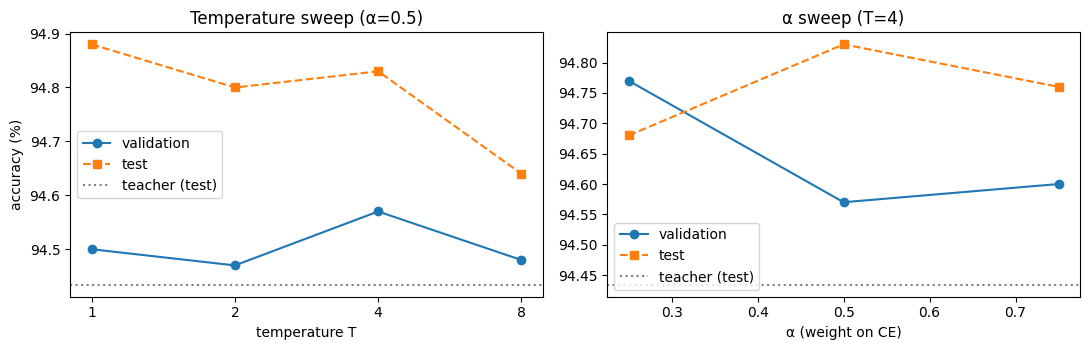

In [18]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t_table["T"], 100 * t_table["val_accuracy"], "o-", label="validation")
ax[0].plot(t_table["T"], 100 * t_table["test_accuracy"], "s--", label="test")
ax[0].axhline(100 * teacher_rec["test_accuracy"], color="gray", ls=":", label="teacher (test)")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(T_SWEEP, [str(t) for t in T_SWEEP])
ax[0].set_xlabel("temperature T"); ax[0].set_ylabel("accuracy (%)"); ax[0].set_title(f"Temperature sweep (α={ALPHA_FOR_T_SWEEP})"); ax[0].legend()
ax[1].plot(a_table["alpha"], 100 * a_table["val_accuracy"], "o-", label="validation")
ax[1].plot(a_table["alpha"], 100 * a_table["test_accuracy"], "s--", label="test")
ax[1].axhline(100 * teacher_rec["test_accuracy"], color="gray", ls=":", label="teacher (test)")
ax[1].set_xlabel("α (weight on CE)"); ax[1].set_title(f"α sweep (T={BEST_T})"); ax[1].legend()
plt.tight_layout(); plt.savefig("figs/part2_sweeps.png", dpi=150); plt.show()

## Training log and loss trends

Sample training log for the best student (one line every `LOG_EVERY` steps; full logs for every run are in `logs/train_log_*.csv` and `RUN_LOG_part2.txt`), followed by loss curves.

Sample training log — alpha0.25_T4 (T=4, alpha=0.25)


,step,epoch,loss,ce,kl,lr,elapsed_s
0,200,1,4.5508,0.7832,5.8067,0.0,18.5795
1,400,1,1.3020,0.4624,1.5819,0.0,37.0144
2,600,1,1.0669,0.4376,1.2766,0.0,56.0141
3,800,1,0.8546,0.3692,1.0165,0.0,74.4945
4,1000,1,0.7995,0.3450,0.9510,0.0,93.3427
5,1200,1,0.7009,0.3034,0.8333,0.0,111.8615
6,1400,1,0.7342,0.3145,0.8740,0.0,130.2817
7,1600,1,0.6471,0.2751,0.7711,0.0,148.9774
8,1800,1,0.6907,0.3028,0.8200,0.0,167.6754
9,2000,1,0.6618,0.2978,0.7832,0.0,186.0044


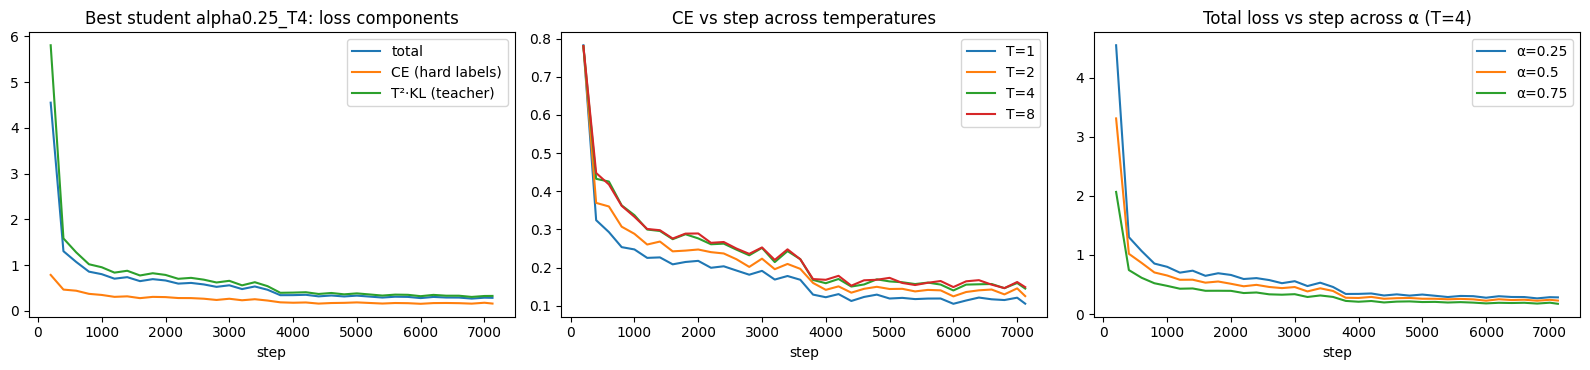

In [19]:
best_hist = pd.DataFrame(HISTORIES[BEST["run"]])
print(f"Sample training log — {BEST['run']} (T={BEST['T']}, alpha={BEST['alpha']})")
display(best_hist.round(4))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(best_hist["step"], best_hist["loss"], label="total")
ax[0].plot(best_hist["step"], best_hist["ce"], label="CE (hard labels)")
ax[0].plot(best_hist["step"], best_hist["kl"], label="T²·KL (teacher)")
ax[0].set_title(f"Best student {BEST['run']}: loss components"); ax[0].set_xlabel("step"); ax[0].legend()
for r in t_runs:
    h = pd.DataFrame(HISTORIES[r["run"]]); ax[1].plot(h["step"], h["ce"], label=f"T={r['T']}")
ax[1].set_title("CE vs step across temperatures"); ax[1].set_xlabel("step"); ax[1].legend()
for r in a_runs:
    h = pd.DataFrame(HISTORIES[r["run"]]); ax[2].plot(h["step"], h["loss"], label=f"α={r['alpha']}")
ax[2].set_title(f"Total loss vs step across α (T={BEST_T})"); ax[2].set_xlabel("step"); ax[2].legend()
plt.tight_layout(); plt.savefig("figs/part2_loss_curves.png", dpi=150); plt.show()

## Final student vs teacher (same AG News test set, same GPU)

In [20]:
student = fresh_student()
student.load_state_dict(BEST["state_dict"]); student.to(DEVICE).eval()
student_rec, student_preds, student_test_logits = benchmark(student, s_tok, s_test_ids, "student_distilbert", "artifacts/student_best")
s_tok.save_pretrained("artifacts/student_best")
student_rec.update({"T": BEST["T"], "alpha": BEST["alpha"], "run": BEST["run"]})

cmp = pd.DataFrame([
    {"Model": "Teacher (BERT)", **{k: teacher_rec[k] for k in ["test_accuracy", "test_set_seconds", "throughput_samples_per_s", "latency_p50_ms", "latency_p95_ms", "peak_gpu_mib", "params_m", "disk_mib"]}},
    {"Model": f"Student (DistilBERT, T={BEST['T']}, α={BEST['alpha']})", **{k: student_rec[k] for k in ["test_accuracy", "test_set_seconds", "throughput_samples_per_s", "latency_p50_ms", "latency_p95_ms", "peak_gpu_mib", "params_m", "disk_mib"]}},
]).set_index("Model").round(4)
display(cmp)
ratios = {
    "accuracy_retained_pct": 100 * student_rec["test_accuracy"] / teacher_rec["test_accuracy"],
    "accuracy_drop_pts": 100 * (teacher_rec["test_accuracy"] - student_rec["test_accuracy"]),
    "test_set_speedup_x": teacher_rec["test_set_seconds"] / student_rec["test_set_seconds"],
    "latency_p50_speedup_x": teacher_rec["latency_p50_ms"] / student_rec["latency_p50_ms"],
    "param_reduction_pct": 100 * (1 - student_rec["params_m"] / teacher_rec["params_m"]),
    "disk_reduction_pct": 100 * (1 - student_rec["disk_mib"] / teacher_rec["disk_mib"]),
}
for k, v in ratios.items(): log(f"{k} = {v:.2f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[01:06:22] [student_distilbert] test acc=0.9468  test-set time=3.02s (2519/s)  latency p50=6.00ms p95=7.48ms  peak GPU=527MiB  params=67.0M  disk=255.4MiB


,test_accuracy,test_set_seconds,throughput_samples_per_s,latency_p50_ms,latency_p95_ms,peak_gpu_mib,params_m,disk_mib
Model,,,,,,,,
Teacher (BERT),0.9443,6.0731,1251.4204,29.7512,56.9053,796.4629,109.4853,417.6767
"Student (DistilBERT, T=4, α=0.25)",0.9468,3.0168,2519.2101,6.0033,7.4820,527.3315,66.9565,255.4317


[01:06:22] accuracy_retained_pct = 100.26
[01:06:22] accuracy_drop_pts = -0.25
[01:06:22] test_set_speedup_x = 2.01
[01:06:22] latency_p50_speedup_x = 4.96
[01:06:22] param_reduction_pct = 38.84
[01:06:22] disk_reduction_pct = 38.84


## Where compression hurts — per-class accuracy

The class with the largest teacher → student accuracy drop is examined; five examples (seeded random sample) that the teacher classifies correctly and the student gets wrong are printed in full.

,teacher,student,drop_pts
World,0.9489,0.9526,-0.3684
Sports,0.9884,0.9889,-0.0526
Business,0.9137,0.9111,0.2632
Sci/Tech,0.9263,0.9347,-0.8421


Teacher confusion matrix


,pred World,pred Sports,pred Business,pred Sci/Tech
true World,1803,10,50,37
true Sports,9,1878,6,7
true Business,33,6,1736,125
true Sci/Tech,28,9,103,1760


Student confusion matrix


,pred World,pred Sports,pred Business,pred Sci/Tech
true World,1810,11,43,36
true Sports,9,1879,6,6
true Business,35,5,1731,129
true Sci/Tech,27,8,89,1776


[01:06:22] most degraded class: Business (teacher 0.9137 -> student 0.9111, drop 0.26 pts)


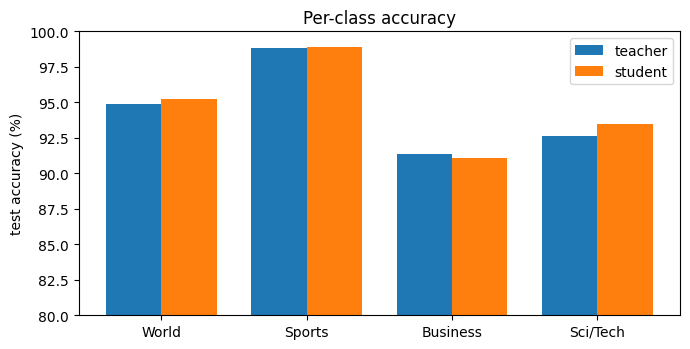

In [21]:
pc = pd.DataFrame({"teacher": teacher_rec["per_class_accuracy"], "student": student_rec["per_class_accuracy"]})
pc["drop_pts"] = 100 * (pc["teacher"] - pc["student"])
display(pc.round(4))

def confusion(y, p):
    m = np.zeros((4, 4), int)
    for a, b in zip(y, p): m[a, b] += 1
    return pd.DataFrame(m, index=[f"true {c}" for c in CLASS_NAMES], columns=[f"pred {c}" for c in CLASS_NAMES])
print("Teacher confusion matrix"); display(confusion(test_labels, teacher_preds))
print("Student confusion matrix"); display(confusion(test_labels, student_preds))

WORST = int(np.argmax(pc["drop_pts"].values)); WORST_NAME = CLASS_NAMES[WORST]
log(f"most degraded class: {WORST_NAME} (teacher {pc.loc[WORST_NAME,'teacher']:.4f} -> student {pc.loc[WORST_NAME,'student']:.4f}, "
    f"drop {pc.loc[WORST_NAME,'drop_pts']:.2f} pts)")

x = np.arange(4); w = 0.38
plt.figure(figsize=(7, 3.6))
plt.bar(x - w/2, 100 * pc["teacher"], w, label="teacher"); plt.bar(x + w/2, 100 * pc["student"], w, label="student")
plt.xticks(x, CLASS_NAMES); plt.ylim(80, 100); plt.ylabel("test accuracy (%)"); plt.legend(); plt.title("Per-class accuracy")
plt.tight_layout(); plt.savefig("figs/part2_per_class.png", dpi=150); plt.show()

In [22]:
t_prob = torch.softmax(teacher_test_logits, 1).numpy(); s_prob = torch.softmax(student_test_logits, 1).numpy()
mask = (test_labels == WORST) & (teacher_preds == WORST) & (student_preds != WORST)
cand = np.where(mask)[0]
log(f"{WORST_NAME}: {len(cand)} test examples teacher-right / student-wrong; student predicted instead: "
    + str({CLASS_NAMES[c]: int((student_preds[cand] == c).sum()) for c in range(4) if c != WORST}))
pick = np.sort(np.random.default_rng(SEED).choice(cand, min(5, len(cand)), replace=False))
EXAMPLES = []
for n, j in enumerate(pick, 1):
    ex = {"test_index": int(j), "text": test_texts[j], "true": WORST_NAME,
          "student_pred": CLASS_NAMES[student_preds[j]],
          "teacher_p_true": float(t_prob[j, WORST]), "student_p_true": float(s_prob[j, WORST]),
          "student_p_pred": float(s_prob[j, student_preds[j]])}
    EXAMPLES.append(ex)
    print(f"--- Example {n} (test idx {j}) | true={WORST_NAME} | student -> {ex['student_pred']} "
          f"(p={ex['student_p_pred']:.2f}) | teacher p(true)={ex['teacher_p_true']:.2f}, student p(true)={ex['student_p_true']:.2f}")
    print(test_texts[j], "\n")

[01:06:22] Business: 45 test examples teacher-right / student-wrong; student predicted instead: {'World': 13, 'Sports': 2, 'Sci/Tech': 30}
--- Example 1 (test idx 2281) | true=Business | student -> World (p=0.78) | teacher p(true)=0.78, student p(true)=0.22
Saudi Arabia, Qatar, Kuwait still risky investments: study (AFP) AFP - Investing remains risky in Saudi Arabia, Qatar and Kuwait, notably because the presence of US forces in the region makes these countries vulnerable to terrorist attacks, a security consulting firm said. 

--- Example 2 (test idx 2914) | true=Business | student -> Sci/Tech (p=0.81) | teacher p(true)=0.82, student p(true)=0.19
Netflix, TiVo sign VoD alliance Netflix, the online DVD rental company, and TiVo yesterday said they will work together to deliver movies digitally down the wires, presumably specifically to the latter #39;s PVR equipment. 

--- Example 3 (test idx 6980) | true=Business | student -> World (p=0.98) | teacher p(true)=1.00, student p(true)=0.02


## Save metrics and logs

In [23]:
part2 = {"teacher_dir": TEACHER_DIR, "student_checkpoint": STUDENT_ID, "gpu": GPU_NAME,
         "fixed_settings": {"max_len": MAX_LEN, "batch_size": BATCH_SIZE, "epochs": EPOCHS, "lr": LR,
                            "weight_decay": WEIGHT_DECAY, "warmup_frac": WARMUP_FRAC, "grad_clip": GRAD_CLIP,
                            "val_frac": VAL_FRAC, "seed": SEED, "amp_fp16": USE_AMP},
         "loss": "alpha*CE(student,y) + (1-alpha)*T^2*KL(softmax(t/T)||softmax(s/T))",
         "temperature_sweep": {"alpha": ALPHA_FOR_T_SWEEP, "runs": t_runs, "best_T": BEST_T},
         "alpha_sweep": {"T": BEST_T, "runs": a_runs, "best_alpha": BEST_ALPHA},
         "teacher": teacher_rec, "student": student_rec, "ratios": ratios,
         "per_class": pc.round(4).to_dict(), "most_degraded_class": WORST_NAME, "examples": EXAMPLES}
json.dump(part2, open("part2_metrics.json", "w"), indent=2)
open("RUN_LOG_part2.txt", "w").write("\n".join(RUN_LOG) + "\n")
print("saved part2_metrics.json, RUN_LOG_part2.txt, logs/, figs/part2_*.png, artifacts/student_best/")

saved part2_metrics.json, RUN_LOG_part2.txt, logs/, figs/part2_*.png, artifacts/student_best/


## Quantization vs distillation (Measurement & analysis item 5)

Relative changes only: the two parts use different models and tasks, so their accuracy/perplexity values are **not** compared directly. Upload `part1_metrics.json` from the Part 1 notebook into this session before running the cell.

In [24]:
if os.path.exists("part1_metrics.json"):
    p1 = json.load(open("part1_metrics.json")); s1 = p1["summary"]
    comp = pd.DataFrame({
        "GPTQ INT4 vs FP16 base (Part 1)": {
            "on-disk size (new / old)": round(s1["disk_ratio_gptq_over_base"], 3),
            "peak GPU memory (new / old)": round(s1["peak_mem_ratio_gptq_over_base"], 3),
            "p50 latency (new / old)": round(s1["generate_p50_ratio_gptq_over_base"], 3),
            "quality change (own metric)": f"perplexity {s1['perplexity_change_pct']:+.2f}%",
            "extra training needed": "none (post-training, ~minutes of calibration)"},
        "DistilBERT student vs BERT teacher (Part 2)": {
            "on-disk size (new / old)": round(student_rec["disk_mib"] / teacher_rec["disk_mib"], 3),
            "peak GPU memory (new / old)": round(student_rec["peak_gpu_mib"] / teacher_rec["peak_gpu_mib"], 3),
            "p50 latency (new / old)": round(student_rec["latency_p50_ms"] / teacher_rec["latency_p50_ms"], 3),
            "quality change (own metric)": f"accuracy {-ratios['accuracy_drop_pts']:+.2f} pts",
            "extra training needed": f"{sum(r['train_minutes'] for r in RESULTS):.0f} min for {len(RESULTS)} student runs"},
    })
    display(comp)
else:
    print("part1_metrics.json not found - upload it to compare.")

part1_metrics.json not found - upload it to compare.


### Written analysis

**Setup.** Instructor BERT teacher (109.5M params) and `distilbert-base-uncased` student (67.0M params), both evaluated on the AG News test set (7,600 examples) on the same Tesla T4. Every student was trained on 114,000 training examples for 2 epochs (batch 32, lr 5e-5 with linear decay, fp16, SEED 6638) and started from the same pretrained checkpoint. The best settings were chosen on a 6,000-example held-out validation split. The teacher's output columns already matched AG News label order (98.7% on the 2,000-example check), so no reordering was needed. Note: the `lr` column in the training log shows `0.0` only because of 4-decimal rounding; the peak learning rate was 5e-5, decaying linearly to 0.

**How much difference is noise.** With accuracy around 94.5%, one standard error is about **0.29 points** on the validation split and **0.26 points** on the test split. Re-running the identical setting (T=4, α=0.5) in the α sweep reproduced its result exactly (val 0.9457, test 0.9483), so the runs are deterministic. The differences between runs come from the settings, but they are small compared with sampling noise.

**Temperature sweep (α = 0.5).**

| T | Val acc | Test acc | Final CE | Final T²·KL |
|---|---|---|---|---|
| 1 | 0.9450 | **0.9488** | 0.105 | 0.076 |
| 2 | 0.9447 | 0.9480 | 0.125 | 0.200 |
| 4 | **0.9457** | 0.9483 | 0.145 | 0.311 |
| 8 | 0.9448 | 0.9464 | 0.149 | 0.336 |

T = 4 has the best validation accuracy and is the selected temperature. All four temperatures fall within 0.10 points on validation and 0.24 points on test, which is about one standard error. Temperature therefore makes no meaningful difference here. Higher T does change how training behaves. The final hard-label CE rises from 0.105 (T=1) to 0.149 (T=8), because the softened targets pull the student away from fitting the one-hot labels exactly. The KL term grows with T because of the T² scale factor, so KL values are not comparable across temperatures. Softening adds little here because the teacher is very confident (98.95% training accuracy) and there are only four classes. Its softened distribution therefore carries little extra between-class information beyond the label itself.

**Loss-weighting sweep (T = 4).**

| α (weight on CE) | Val acc | Test acc | Final CE | Final T²·KL |
|---|---|---|---|---|
| 0.25 | **0.9477** | 0.9468 | 0.157 | 0.324 |
| 0.50 | 0.9457 | **0.9483** | 0.145 | 0.311 |
| 0.75 | 0.9460 | 0.9476 | 0.128 | 0.309 |

α = 0.25 (mostly teacher signal) has the best validation accuracy, so the final student uses **T = 4, α = 0.25**. Validation and test disagree on the ranking: α = 0.25 is best on validation and worst on test. The whole spread is about 0.2 points, again within noise. Raising α lowers the final CE (0.157 → 0.128), as expected when the hard labels get more weight.

**Loss trends.** For the selected student, total loss fell from 4.55 at step 200 to 0.28 at the end. The T²·KL term starts high (5.8, inflated by T² = 16) and drops fastest as the student learns to match the teacher. The CE term falls more gradually (0.78 → 0.16). Every run shows a clear step down at the start of epoch 2 (around step 3,600), and the losses flatten after that.

**Teacher vs. distilled student (same test set, same T4).**

| | Teacher (BERT) | Student (DistilBERT, T=4, α=0.25) | Change |
|---|---|---|---|
| Test accuracy | 0.9443 | 0.9468 | +0.25 pts |
| Full test set, batch 64 | 6.07 s (1,251/s) | 3.02 s (2,519/s) | **2.0× faster** |
| Batch-1 latency p50 / p95 | 29.8 / 56.9 ms | 6.0 / 7.5 ms | see note |
| Peak GPU memory | 796 MiB | 527 MiB | −34% |
| Parameters | 109.5M | 67.0M | −38.8% |
| On-disk size | 418 MiB | 255 MiB | −38.8% |

The student keeps all of the teacher's accuracy; on paper it is 0.25 points higher (≈19 examples), which is within noise. A plausible reason it does not fall behind is that the teacher overfits somewhat (98.95% train vs 94.43% test accuracy). The student also gets the hard labels, and the teacher's soft targets act as a regulariser. The 2.0× throughput gain matches halving the transformer layers from 12 to 6. Size falls by only 39%, not 50%, because the 23M-parameter embedding layer is the same size in both models. **Note on batch-1 latency:** the 5× gap is larger than halving the layers can explain, and the teacher's p95 is almost twice its p50. The teacher's single-example timing was taken first in the session, right after logit extraction, with no batch-1 warm-up, so it is probably inflated. The 2.0× batched figure is the more reliable speedup.

**Where compression hurts.** Per-class accuracy, teacher → student: World 94.89 → 95.26, Sports 98.84 → 98.89, **Business 91.37 → 91.11**, Sci/Tech 92.63 → 93.47. Business is the only class that degrades, by just 0.26 points (5 examples net). The 45 Business examples the teacher gets right and the student gets wrong are almost balanced by ones that go the other way. Of those 45, the student labelled 30 as Sci/Tech and 13 as World. Business→Sci/Tech is also the largest confusion for both models (125 for the teacher, 129 for the student).

*What the five examples have in common:* each one is a business story (investment risk, a distribution deal, airline expansion, currency policy, wholesale pricing) told mostly in another class's vocabulary. Three read like World news: Gulf states and US forces, Sir Richard Branson and city names, and Bush meeting Berlusconi, which is a photo caption whose only business cue is "strong-dollar" in the headline. Two read like Sci/Tech: Netflix/TiVo video-on-demand, and broadband pricing set by Ofcom. In each case the economic signal is one or two words ("investments", "alliance", "strong-dollar", "charges"), often only in the headline. The teacher picks up that cue, while the shallower student follows the dominant topic words. Several are borderline for the teacher too: its probability for the true label was 0.78, 0.82 and 0.51 on three of the five. Some, such as Netflix/TiVo and broadband pricing, are arguably mislabelled or really belong to two classes.

**Quantization vs. distillation.** The ratios below come from Part 1 (OPT-125M, run on an L4) and Part 2 (BERT → DistilBERT, run on a T4). The tasks and hardware differ, so only relative changes are compared; quality is given in each part's own metric.

| Relative to the uncompressed model | GPTQ INT4 (Part 1) | Distillation (Part 2) |
|---|---|---|
| On-disk size | 0.51× | 0.61× |
| Peak GPU memory | 0.92× (weights alone 0.48×) | 0.66× |
| Latency / throughput | 2.0× **slower** (p50 generation) | 2.0× **faster** (test-set throughput) |
| Quality, in its own metric | perplexity +11.6% | accuracy +0.25 pts (no loss) |
| Cost to produce | ~107 s calibration, no training | 7 runs × 11 min (one run once T and α are chosen) |

Quantization and distillation compress models in different ways. GPTQ stores the same network at lower precision: it halved weight memory and disk size in under two minutes with no training. On OPT-125M, however, it cost 11.6% in perplexity and made batch-1 inference about 2× slower, because the INT4 kernels add dequantisation work to a model too small to be limited by memory bandwidth. Distillation builds a smaller network: it cut parameters, disk and peak memory by roughly 35–40% and doubled throughput while keeping the teacher's accuracy, but it needed a full training run plus tuning of T and α. For a **latency-bound** deployment I would try **distillation first**, because removing layers reduces the compute in every forward pass, whereas GPTQ gave no speedup at this model size. For a **memory-bound** deployment I would try **quantization first**, because it roughly halves weight memory with no retraining and can be applied on top of a distilled model afterwards.
